In [3]:
options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

In [4]:
library('tidymodels')

gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

── Attaching packages ────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ───────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Use tidymodels_prefer() to resolve common conflicts.


Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


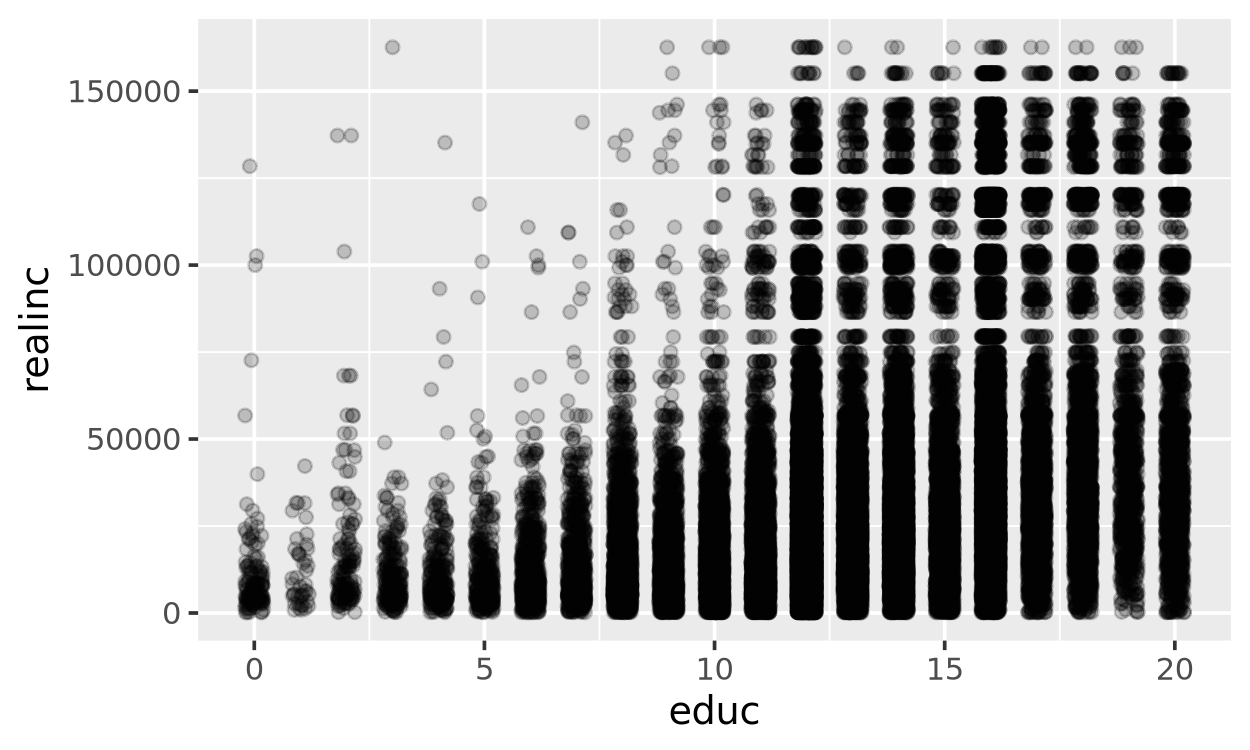

In [11]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.2, position = position_jitter(width = 0.2, height = 0.2))

In [ ]:
# predictor
# feature
# regressor

In [15]:
set.seed(123)
n_combos = 250

params = tibble(
    .rep = 1:n_combos,
    intercept = runif(n_combos, -50000, 50000),
    slope = runif(n_combos, 0, 5000)
)

params |> glimpse()

Rows: 250
Columns: 3
$ .rep      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> -21242.248, 28830.514, -9102.308, 38301.740, 44046.728, -454…
$ slope     <dbl> 1286.08373, 1108.93967, 2965.22826, 1337.60716, 2655.35199, …


Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


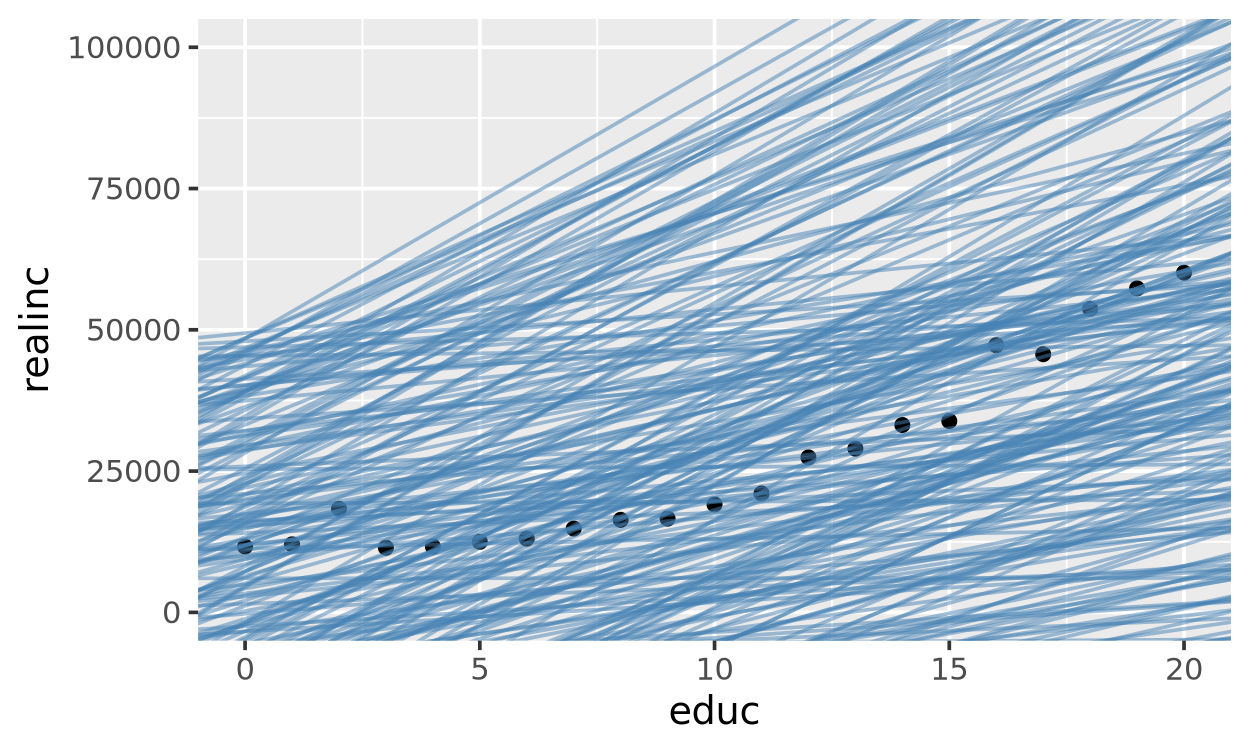

In [19]:
gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc, na.rm = TRUE)) |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_point() +
    geom_abline(
        data = params,
        aes(intercept = intercept, slope = slope),
        alpha = 0.5, color = 'steelblue'
    ) +
    coord_cartesian(ylim = c(0, 100000))

Steps for creating a model:

1. Pick the model form: a linear model

$$\text{realinc} = \text{intercept} + \text{slope} \cdot \text{educ}$$

2. Design a way to evaluate different model parameters.
3. Optimize our paramater values.

In [10]:
rmse_fn = function(intercept, slope, data = gss) {
    pred = intercept + slope * data$educ
    resid = data$realinc - pred # short for residual
    sqrt(mean(resid^2, na.rm = TRUE))
}

rmse_fn(intercept = 0, slope = 2500)

[1] 28504.88

In [20]:
params = params |>
    rowwise() |>
    mutate(rmse = rmse_fn(intercept, slope)) |>
    ungroup()

params |> glimpse()

Rows: 250
Columns: 4
$ .rep      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> -21242.248, 28830.514, -9102.308, 38301.740, 44046.728, -454…
$ slope     <dbl> 1286.08373, 1108.93967, 2965.22826, 1337.60716, 2655.35199, …
$ rmse      <dbl> 47049.63, 31296.36, 28490.15, 37355.48, 54436.77, 38692.53, …


Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


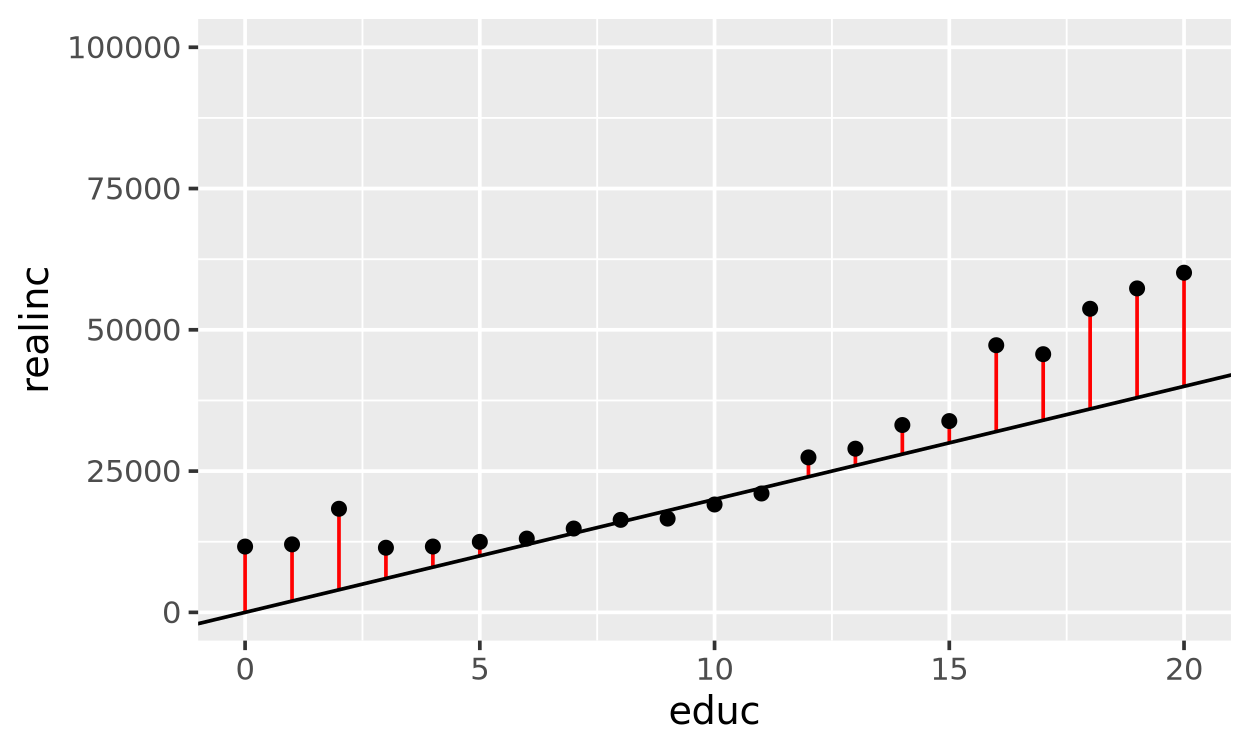

In [40]:
model_intercept = 0
model_slope = 2000

gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc, na.rm = TRUE)) |>
    mutate(pred = model_intercept + model_slope * educ) |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_segment(aes(xend = educ, yend = pred), color = 'red') +
    geom_point() +
    geom_abline(intercept = model_intercept, slope = model_slope) +
    coord_cartesian(ylim = c(0, 100000))

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


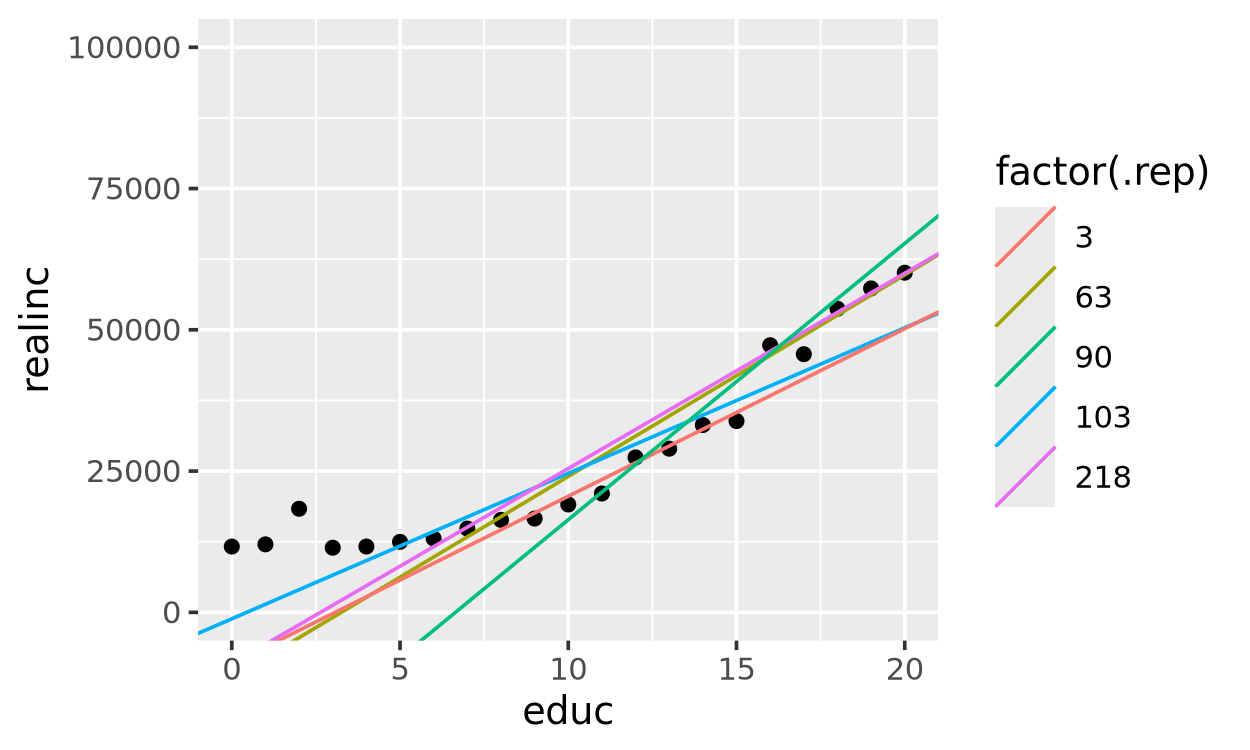

In [44]:
best5 = params |> slice_min(rmse, n = 5)

gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc, na.rm = TRUE)) |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_point() +
    geom_abline(
        data = best5,
        aes(intercept = intercept, slope = slope, color = factor(.rep))
    ) +
    coord_cartesian(ylim = c(0, 100000))

In [ ]:
# What values for slope and intercept minimize RMSE?



## Algorithm - Random search

1. Give me some random slope and intercept values
2. Calculate RMSE for all combos
3. Found the best line
4. Now we have a slope and intercept for the model

## Algorithm - Grid search

1. Give me some grid of slope and intercept values
2. Calculate RMSE for all combos
3. Found the best line
4. Now we have a slope and intercept for the model

In [8]:
seq(-25000, -5000, length = 25)

 [1] -25000.000 -24166.667 -23333.333 -22500.000 -21666.667 -20833.333
 [7] -20000.000 -19166.667 -18333.333 -17500.000 -16666.667 -15833.333
[13] -15000.000 -14166.667 -13333.333 -12500.000 -11666.667 -10833.333
[19] -10000.000  -9166.667  -8333.333  -7500.000  -6666.667  -5833.333
[25]  -5000.000

In [17]:
grid <- expand_grid(
    intercept = seq(-25000, -5000, length = 500),
    slope = seq(2500, 4500, length = 500)
) |>
   mutate(dist = map2_dbl(intercept, slope, rmse_fn))

grid |> head()

  intercept slope    dist    
1 -25000    2500.000 37702.02
2 -25000    2583.333 36970.70
3 -25000    2666.667 36259.68
4 -25000    2750.000 35570.16
5 -25000    2833.333 34903.42
6 -25000    2916.667 34260.79

In [18]:
grid |> slice_min(dist, n = 5)  # dist = rmse

  intercept slope    dist    
1 -13333.33 3500.000 28301.22
2 -15833.33 3666.667 28301.81
3 -14166.67 3583.333 28302.72
4 -15000.00 3583.333 28303.15
5 -12500.00 3416.667 28304.59

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


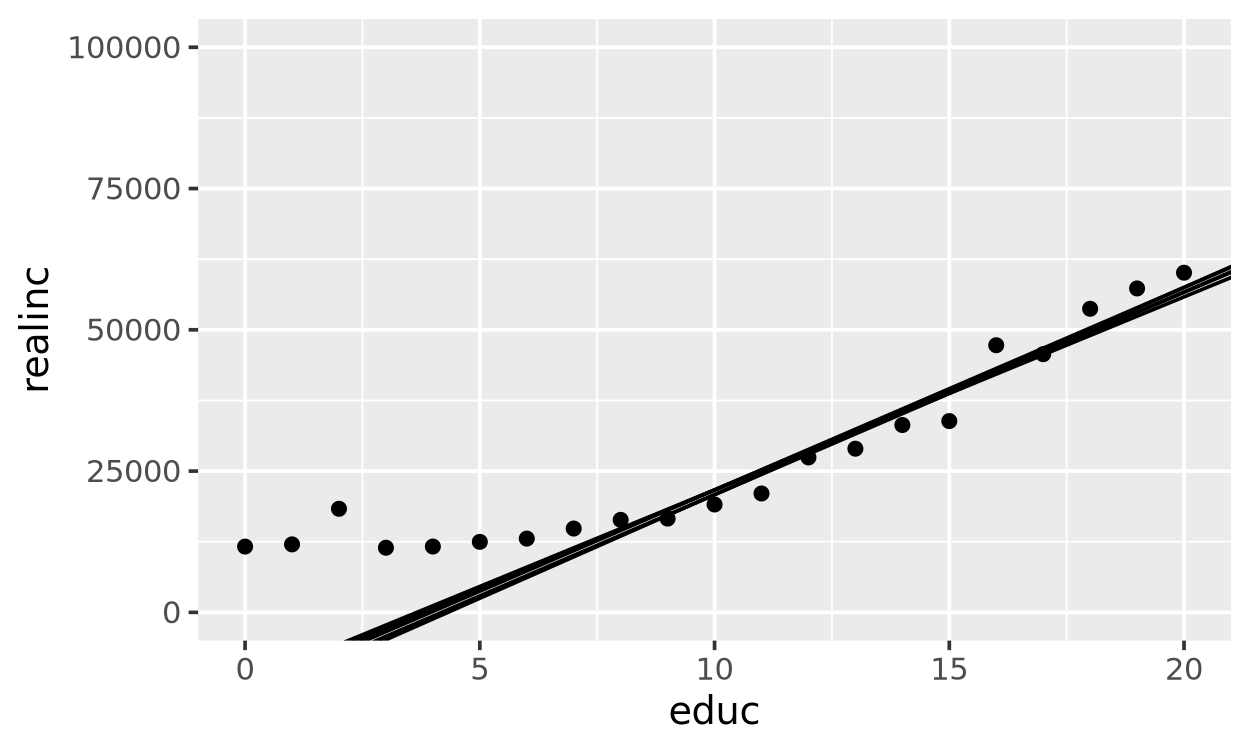

In [19]:
best5 = grid |> slice_min(dist, n = 5)

gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc, na.rm = TRUE)) |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_point() +
    geom_abline(
        data = best5,
        aes(intercept = intercept, slope = slope)
    ) +
    coord_cartesian(ylim = c(0, 100000))

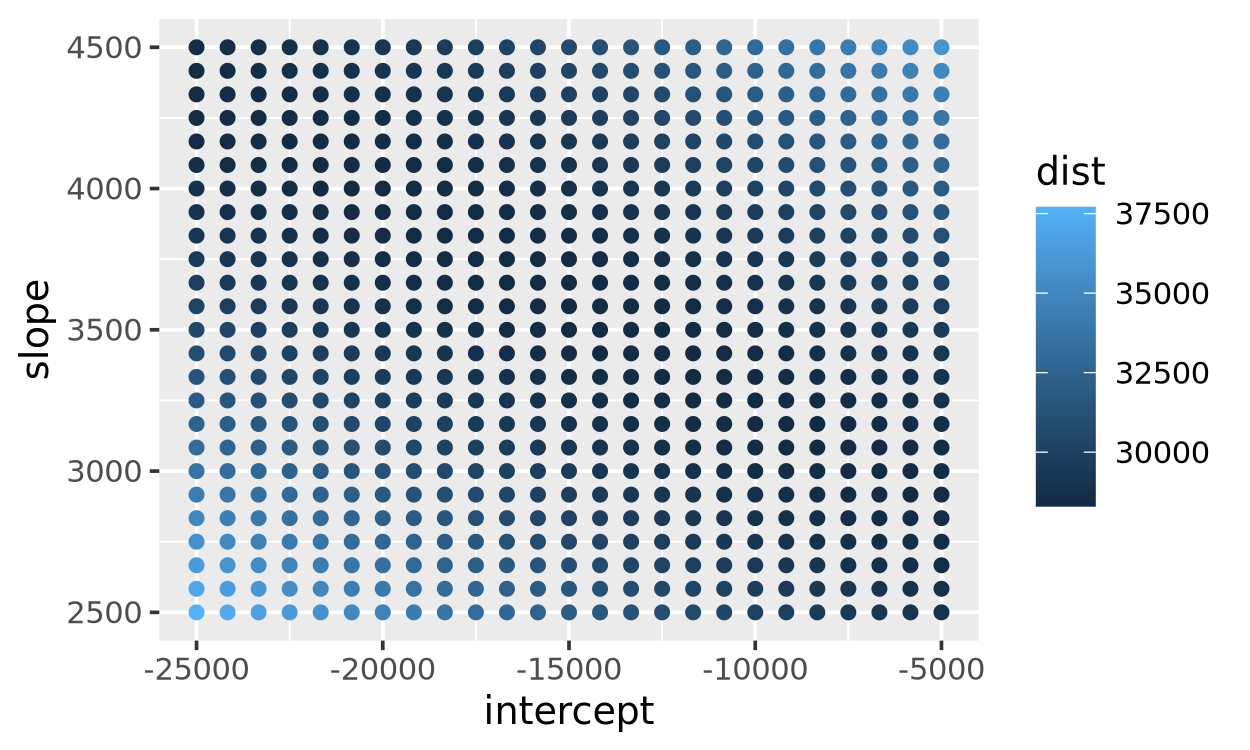

In [20]:
ggplot(grid, aes(x = intercept, y = slope, color = dist)) + geom_point()

## Tidymodels

In [21]:
mod = linear_reg()

mod

Linear Regression Model Specification (regression)

Computational engine: lm 


In [34]:
mod_fit = mod |> fit(realinc ~ educ, data = gss)  # "fit" means find the optimal parameter values
                                                  # formula syntax

mod_fit

parsnip model object


Call:
stats::lm(formula = realinc ~ educ, data = data)

Coefficients:
(Intercept)         educ  
     -14472         3576  


## Marginal effect

The marginal effect of education on income is $3,576

Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 286 rows containing missing values or values outside the scale range (`geom_line()`).”


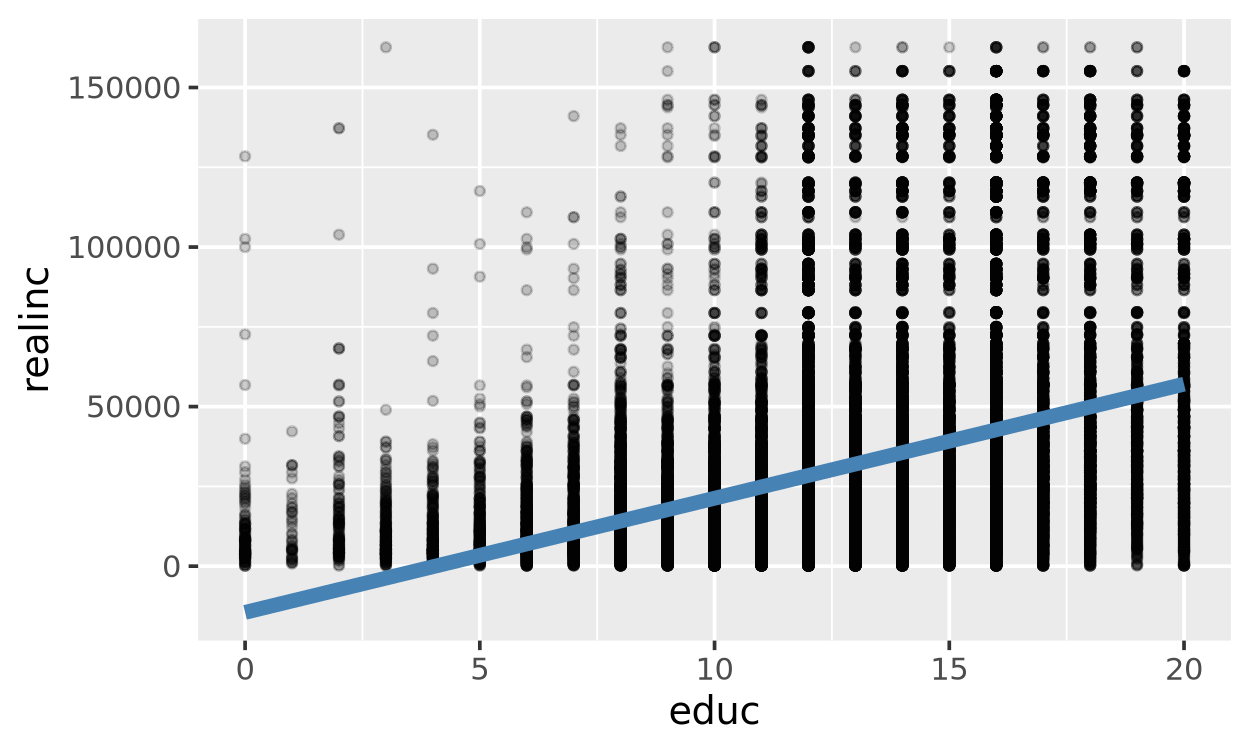

In [38]:
predict(mod_fit, gss) |> bind_cols(gss) |> 
ggplot(aes(x = educ, y = realinc)) + 
    geom_point(alpha = 0.2, size = 1) +
    geom_line(aes(y = .pred), color = 'steelblue', linewidth = 2)
    

Warning message:
“Removed 286 rows containing missing values or values outside the scale range (`geom_line()`).”


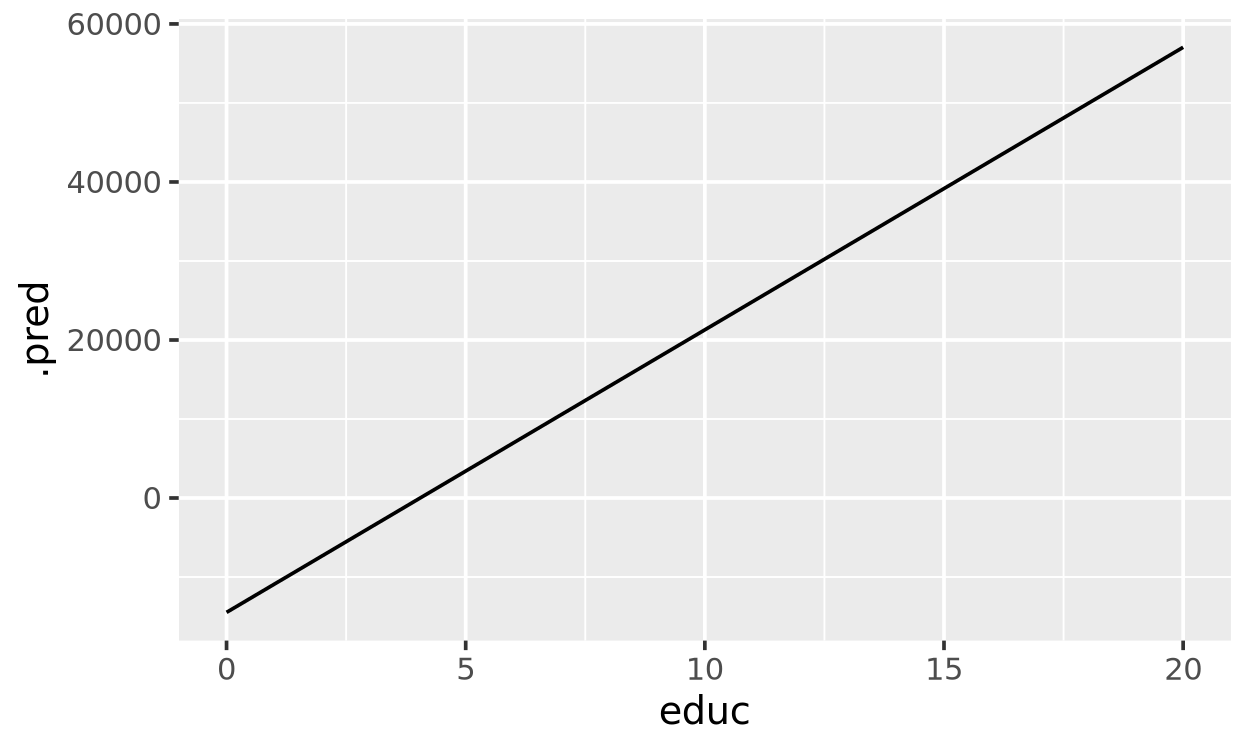

In [33]:
predict(mod_fit, gss) |> bind_cols(gss) |>
ggplot(aes(x = educ, y = .pred)) + geom_line()

In [40]:
gss2 = gss |> mutate(educ_squared = educ ^ 2)

gss2 |> head()

  year id age educ sex gunlaw grass realinc educ_squared
1 1972 1  23  16   2   1      NA    18951   256         
2 1972 2  70  10   1   1      NA    24366   100         
3 1972 3  48  12   2   1      NA    24366   144         
4 1972 4  27  17   2   1      NA    30458   289         
5 1972 5  61  12   2   1      NA    50763   144         
6 1972 6  26  14   1   2      NA    43994   196         

In [41]:
mod_fit = mod |> fit(realinc ~ educ + educ_squared, data = gss2)  # "fit" means find the optimal parameter values
                                                  # formula syntax

mod_fit

parsnip model object


Call:
stats::lm(formula = realinc ~ educ + educ_squared, data = data)

Coefficients:
 (Intercept)          educ  educ_squared  
     10802.2        -729.6         171.4  


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 286 rows containing missing values or values outside the scale range (`geom_line()`).”


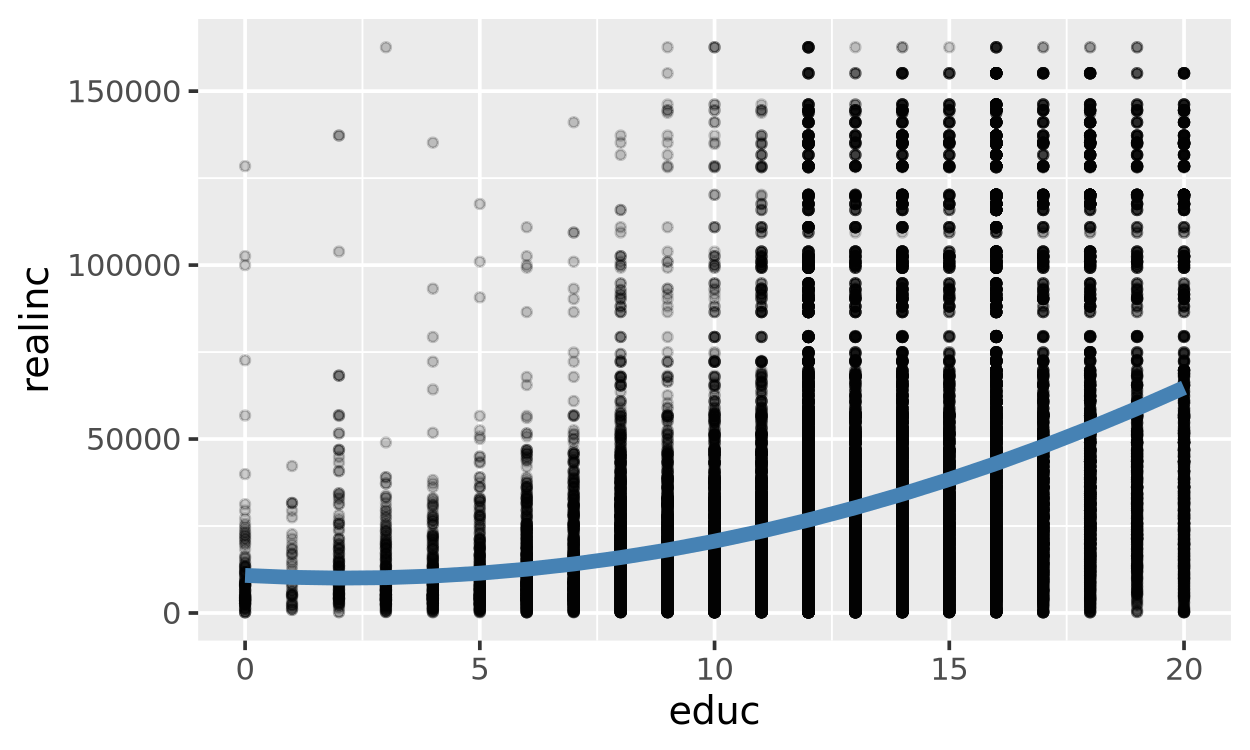

In [42]:
predict(mod_fit, gss2) |> bind_cols(gss2) |> 
ggplot(aes(x = educ, y = realinc)) + 
    geom_point(alpha = 0.2, size = 1) +
    geom_line(aes(y = .pred), color = 'steelblue', linewidth = 2)
    

In [ ]:
# no single value for the marginal effect of educ on income
# 